# Conjugate Bayesian Inference in `probability`
This notebook demonstrates analytical conjugate Bayesian inference for continuous normal data:
1. **`GammaNormalConjugate`**: Known mean $\mu$, unknown precision $\tau = 1/\sigma^2$
2. **`InverseGammaNormalConjugate`**: Known mean $\mu$, unknown variance $\sigma^2$
3. **`NormalInverseGammaConjugate`**: Joint unknown mean $\mu$ and variance $\sigma^2$ with Student-$t$ predictive distributions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from probability.distributions.conjugate import (
    GammaNormalConjugate,
    InverseGammaNormalConjugate,
    NormalInverseGammaConjugate
)
from probability.distributions import Ratio

## 1. Known Mean, Unknown Variance (`InverseGammaNormalConjugate`)
When the true mean $\mu$ is known (e.g. machine calibration centered at zero error), the conjugate prior for $\sigma^2$ is $\text{InverseGamma}(\alpha, \beta)$.

Prior variance: InverseGamma(α=2, β=10)
Posterior variance: InverseGamma(α=27, β=213.657)
95% HDI for sigma^2: (np.float64(5.314910896418815), np.float64(11.511574243908703))


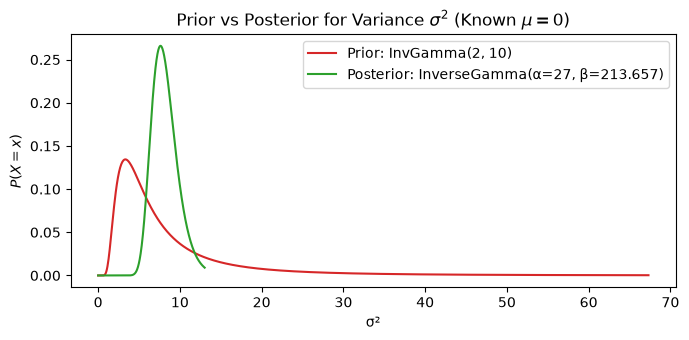

In [2]:
np.random.seed(42)
x_sample = np.random.normal(loc=0.0, scale=3.0, size=50)
conj_var = InverseGammaNormalConjugate(alpha=2.0, beta=10.0, x=x_sample, mu=0.0)

print("Prior variance:", conj_var.prior())
print("Posterior variance:", conj_var.posterior())
print("95% HDI for sigma^2:", conj_var.posterior().hdi(0.95))

fig, ax = plt.subplots(figsize=(7, 3.5))
conj_var.prior().plot(ax=ax, color='tab:red', label='Prior')
conj_var.posterior().plot(ax=ax, color='tab:green', label='Posterior')
ax.set_title("Prior vs Posterior for Variance $\sigma^2$ (Known $\mu=0$)")
ax.legend()
plt.tight_layout();

## 2. Joint Unknown Mean and Variance (`NormalInverseGammaConjugate`)
In typical real-world continuous data, both the mean $\mu$ and variance $\sigma^2$ are unknown. The joint conjugate model gives:
- Marginal posterior $\mu \mid D \sim \text{StudentsT}$
- Marginal posterior $\sigma^2 \mid D \sim \text{InverseGamma}$
- Posterior predictive $\tilde{x} \mid D \sim \text{StudentsT}$

In [3]:
np.random.seed(123)
data = pd.Series(np.random.normal(loc=15.0, scale=4.0, size=60), name='Measurements')
model_joint = NormalInverseGammaConjugate.infer_posterior(data)

print("Model:", model_joint)
print("Marginal posterior mean mu:", model_joint.posterior_mu())
print("95% HDI for mu:", model_joint.posterior_mu().hdi(0.95))
print("Marginal posterior sigma^2:", model_joint.posterior_sigma_sq())
print("95% HDI for sigma^2:", model_joint.posterior_sigma_sq().hdi(0.95))
print("Posterior predictive distribution:", model_joint.posterior_predictive())
print("95% HDI for x_new:", model_joint.posterior_predictive().hdi(0.95))

Model: NormalInverseGammaConjugate(μ₀=0, κ₀=0.001, α₀=0.001, β₀=0.001, n=60)
Marginal posterior mean mu: StudentsT($\nu$=60.002, μ=15.372, σ=0.615)
95% HDI for mu: (np.float64(14.142047246398759), np.float64(16.60223722758616))
Marginal posterior sigma^2: InverseGamma(α=30.001, β=680.742)
95% HDI for sigma^2: (np.float64(15.57421952596344), np.float64(32.365822036495594))
Posterior predictive distribution: StudentsT($\nu$=60.002, μ=15.372, σ=4.803)
95% HDI for x_new: (np.float64(5.7647144869340465), np.float64(24.97956998705087))


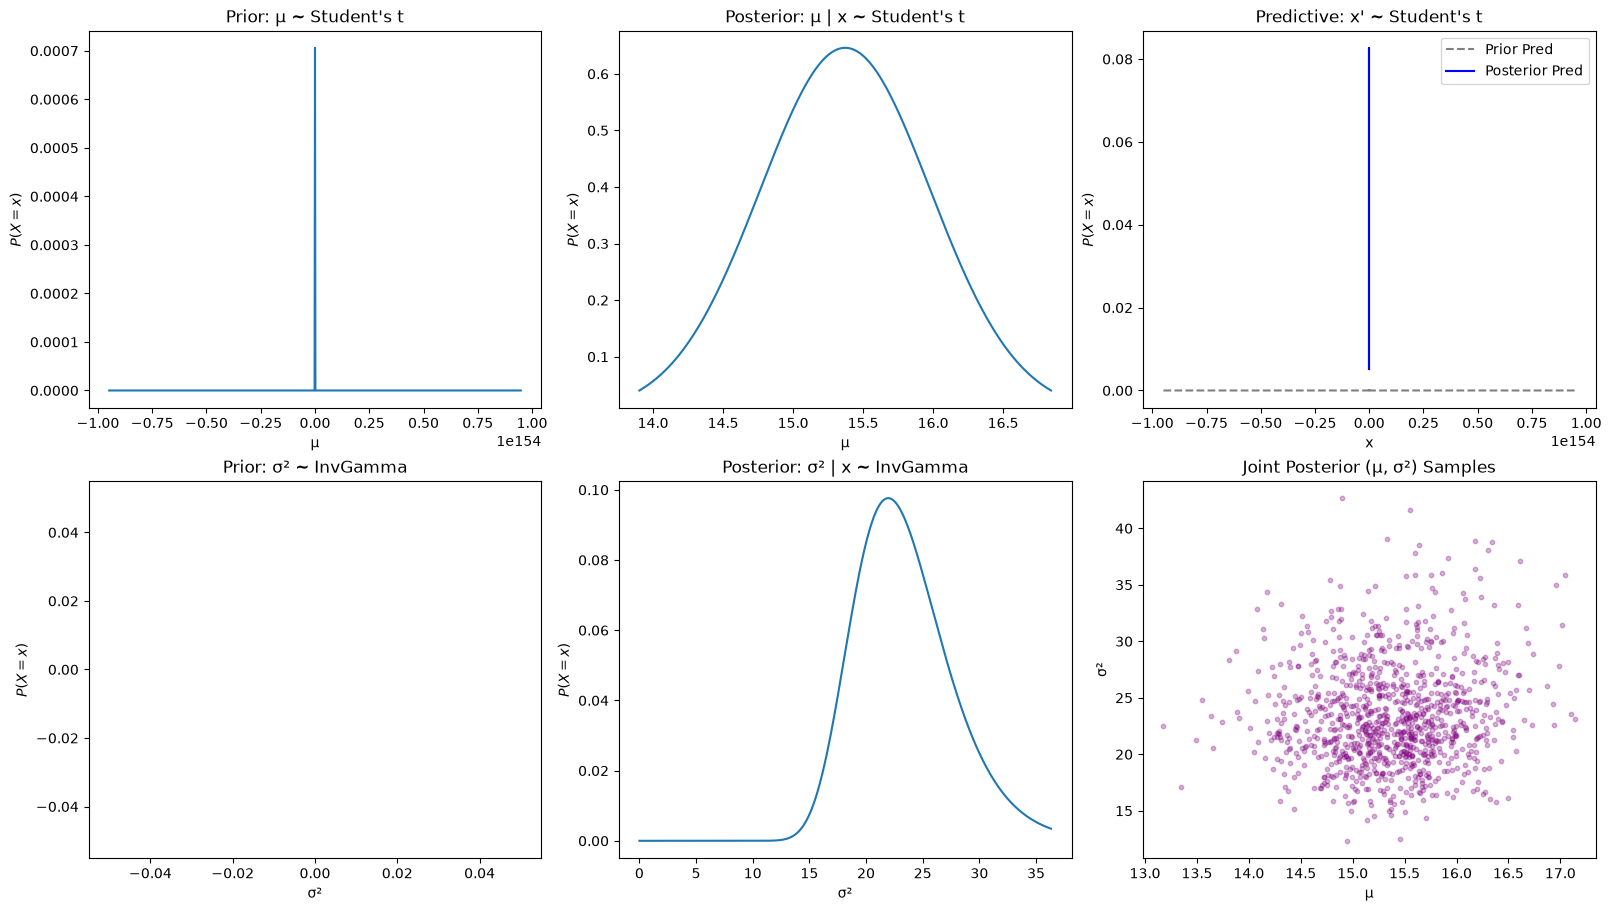

In [4]:
# Visual 2x3 dashboard of Prior vs Posterior Marginals, Joint Sampling, and Predictive Distribution
fig = model_joint.plot()
plt.show();